In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import os
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, OneHotEncoder
import joblib

import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))
from src.utils import (
    load_data,
    class_distribution,
)

## ***1. Wczytanie danych***

In [2]:
IMAGE_PATH = '../dataset/HAM10000_images'
METADATA_PATH = '../dataset/HAM10000_metadata'

In [3]:
df = load_data(Path(METADATA_PATH))
df['Path'] = IMAGE_PATH + os.sep + df['image_id'] + ".jpg"

print(f"Wymiary: ({df.shape[0]}, {df.shape[1]})")
df.head(5)

Dataset loaded.
Wymiary: (10015, 9)


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset,Path
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern,../dataset/HAM10000_images/ISIC_0027419.jpg
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern,../dataset/HAM10000_images/ISIC_0025030.jpg
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern,../dataset/HAM10000_images/ISIC_0026769.jpg
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern,../dataset/HAM10000_images/ISIC_0025661.jpg
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern,../dataset/HAM10000_images/ISIC_0031633.jpg


## ***2. Podział zbioru***

Zbiór danych zostanie podzielony na część treningową (64%), walidacyjną (16%) i testową (20%) według kolumny `lesion_id` by zapobiec wyciekowi danych.

In [4]:
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    sgkf.split(
        X=df,
        y=df['dx'],
        groups=df['lesion_id']
    )
)

train_val_df = df.iloc[train_val_idx].copy()
test_df = df.iloc[test_idx].copy()

sgkf_val = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=43
)

train_idx, val_idx = next(
    sgkf_val.split(
        X=train_val_df,
        y=train_val_df['dx'],
        groups=train_val_df['lesion_id']
    )
)

train_df = train_val_df.iloc[train_idx].copy()
val_df = train_val_df.iloc[val_idx].copy()

print(f"Rozmiar zbioru treningowego: {len(train_df)} zdjęć")
print(f"Rozmiar zbioru walidacyjnego: {len(val_df)} zdjęć")
print(f"Rozmiar zbioru testowego: {len(test_df)} zdjęć")

Rozmiar zbioru treningowego: 6409 zdjęć
Rozmiar zbioru walidacyjnego: 1602 zdjęć
Rozmiar zbioru testowego: 2004 zdjęć


#### Weryfikacja braku przecieku danych

In [5]:
train_lesions = set(train_df['lesion_id'])
val_lesions = set(val_df['lesion_id'])
test_lesions = set(test_df['lesion_id'])

assert train_lesions.isdisjoint(test_lesions)
assert train_lesions.isdisjoint(val_lesions)
assert val_lesions.isdisjoint(test_lesions)

### 2.1. Zbadanie dystrybucji klas w stworzonych zbiorach

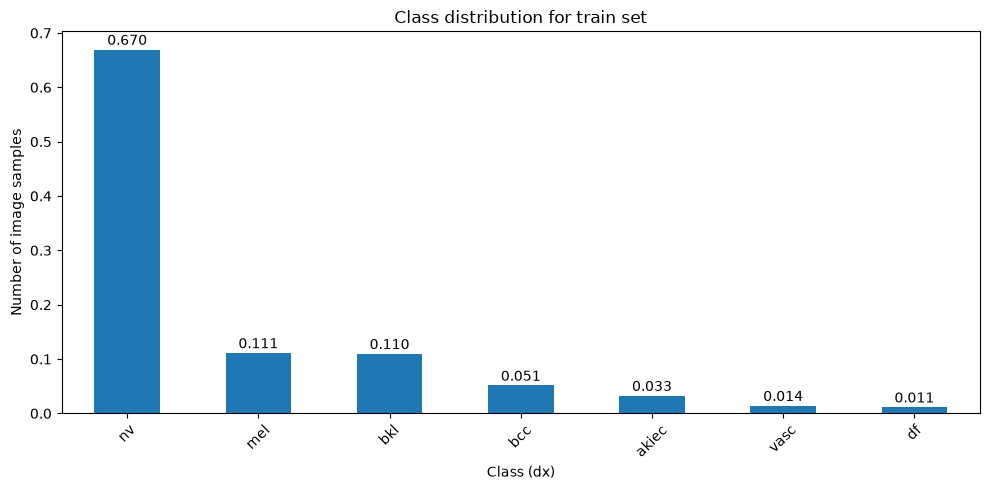

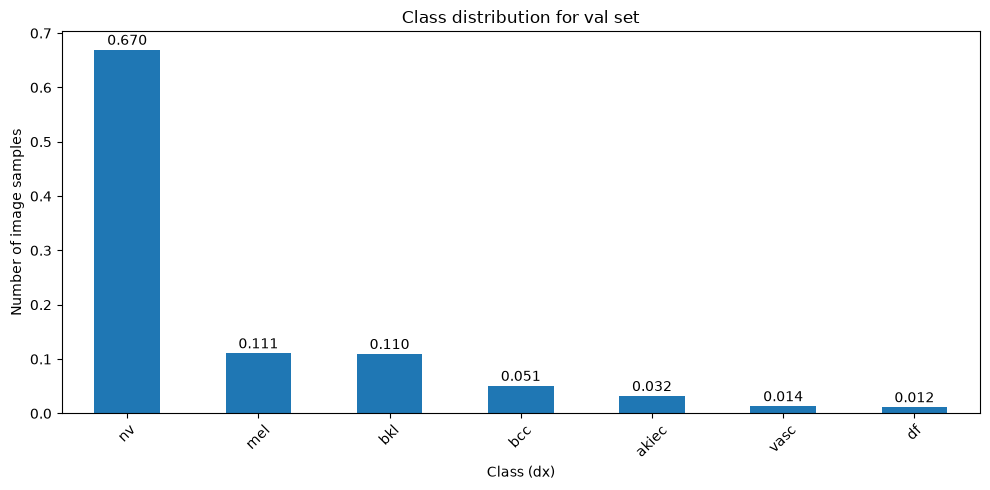

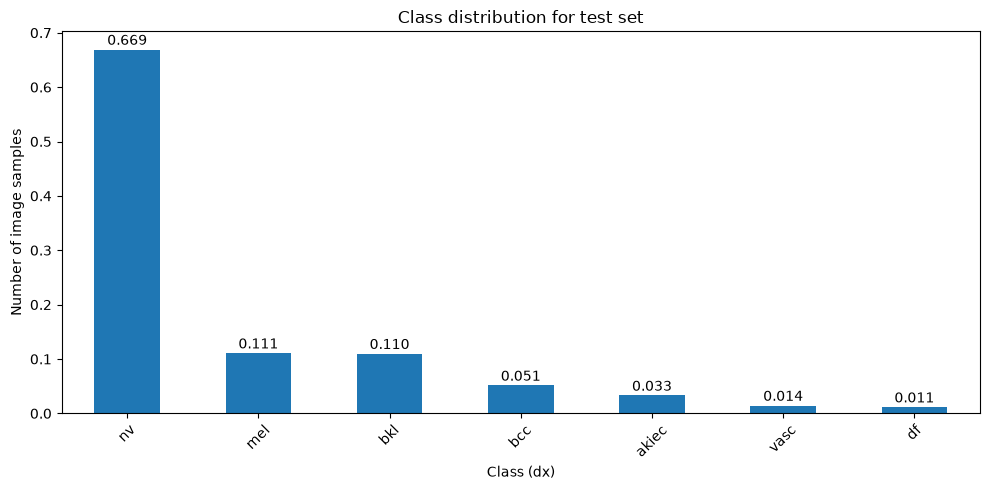

In [6]:
class_distribution(train_df, normalize=True, name="for train set")
class_distribution(val_df, normalize=True, name="for val set")
class_distribution(test_df, normalize=True, name="for test set")

***Wniosek:*** Stosunek klas pozostaje w obu zbiorach na podobnym poziomie, co oznacza, że podział odbył się prawidłowo.

## ***3. Obsługa pustych lub nieznanych wartości***

Brakujące wartości w kolumnie `age` zostaną zapełnione medianą zbioru treningowego. Natomiast w przypadku wartości 'unknown' w kolumnie `sex`, zostaną one zastąpione dominantą zbioru treningowego. Użycie danych zagregowanych zbioru treningowego w zbiorze testowym ma symulować warunki świata rzeczywistego, jako że część testowa reprezentuje nowe, nieznane dane.

a) kolumna `age` - puste wartości zostaną zastąpione medianą zbioru treningowego.

In [7]:
median_age_train = train_df['age'].median()
print(f"\nObliczona ogólna mediana wieku (zbiór treningowy): {median_age_train}")

train_df['age'] = train_df['age'].fillna(median_age_train)
val_df['age'] = val_df['age'].fillna(median_age_train)
test_df['age'] = test_df['age'].fillna(median_age_train)

print(f"Liczba braków age (treningowy po imputacji): {train_df['age'].isnull().sum()}")
print(f"Liczba braków age (walidacyjny po imputacji): {val_df['age'].isnull().sum()}")
print(f"Liczba braków age (testowy po imputacji): {test_df['age'].isnull().sum()}")


Obliczona ogólna mediana wieku (zbiór treningowy): 50.0
Liczba braków age (treningowy po imputacji): 0
Liczba braków age (walidacyjny po imputacji): 0
Liczba braków age (testowy po imputacji): 0


b) kolumna `sex` - nieznane wartości zostaną uzupełnione dominantą zbioru treningowego

In [8]:
train_sex_mode = train_df[train_df['sex'] != 'unknown']['sex'].mode()[0]
print(f"Wyliczona dominanta dla płci: {train_sex_mode}")

train_df['sex'] = train_df['sex'].replace('unknown', train_sex_mode)
val_df['sex'] = val_df['sex'].replace('unknown', train_sex_mode)
test_df['sex'] = test_df['sex'].replace('unknown', train_sex_mode)

print(f"Pozostałe 'unknown' w sex (treningowy): {(train_df['sex'] == 'unknown').sum()}")
print(f"Pozostałe 'unknown' w sex (walidacyjny): {(val_df['sex'] == 'unknown').sum()}")
print(f"Pozostałe 'unknown' w sex (testowy): {(test_df['sex'] == 'unknown').sum()}")

Wyliczona dominanta dla płci: male
Pozostałe 'unknown' w sex (treningowy): 0
Pozostałe 'unknown' w sex (walidacyjny): 0
Pozostałe 'unknown' w sex (testowy): 0


c) kolumna `localization` - wartości `unknown` zostaną potraktowane jako osobna kategoria,.

## ***4. Kodowanie i Normalizacja danych***

### 4.1. Normalizacja kolumny age

In [9]:
min_max_scaler = MinMaxScaler()

train_df['age_normalized'] = min_max_scaler.fit_transform(train_df[['age']])
val_df['age_normalized'] = min_max_scaler.transform(val_df[['age']])
test_df['age_normalized'] = min_max_scaler.transform(test_df[['age']])

print("Podgląd oryginalnego wieku i transformacji:")
print(train_df[['age', 'age_normalized']].head(10))

Podgląd oryginalnego wieku i transformacji:
     age  age_normalized
0   80.0        0.941176
1   80.0        0.941176
6   60.0        0.705882
7   60.0        0.705882
8   70.0        0.823529
9   70.0        0.823529
11  85.0        1.000000
12  85.0        1.000000
13  70.0        0.823529
14  70.0        0.823529


In [10]:
train_df=train_df.drop(columns=['age'])
val_df=val_df.drop(columns=['age'])
test_df=test_df.drop(columns=['age'])

### 4.2. One-Hot Encoding danych kategorycznych

#### a) kolumna `sex` i `localization`

In [11]:
train_df['sex_original'] = train_df['sex']

In [12]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

categorical_columns = ['sex', 'localization']

encoder.fit(train_df[categorical_columns])

train_encoded = encoder.transform(train_df[categorical_columns])
val_encoded = encoder.transform(val_df[categorical_columns])
test_encoded = encoder.transform(test_df[categorical_columns])

In [13]:
encoded_columns = encoder.get_feature_names_out(categorical_columns)

train_encoded_df = pd.DataFrame(
    train_encoded,
    columns=encoded_columns,
    index=train_df.index
)

val_encoded_df = pd.DataFrame(
    val_encoded,
    columns=encoded_columns,
    index=val_df.index
)

test_encoded_df = pd.DataFrame(
    test_encoded,
    columns=encoded_columns,
    index=test_df.index
)

train_df = train_df.drop(columns=categorical_columns)
val_df = val_df.drop(columns=categorical_columns)
test_df = test_df.drop(columns=categorical_columns)

train_df = pd.concat(
    [train_df, train_encoded_df],
    axis=1
)

val_df = pd.concat(
    [val_df, val_encoded_df],
    axis=1
)

test_df = pd.concat(
    [test_df, test_encoded_df],
    axis=1
)

In [14]:
print("Podgląd nowych kolumn po kodowaniu płci:")
display(train_df[['sex_original', 'sex_male', 'sex_female']].head(10))

Podgląd nowych kolumn po kodowaniu płci:


,sex_original,sex_male,sex_female
0,male,1.0,0.0
1,male,1.0,0.0
6,male,1.0,0.0
7,male,1.0,0.0
8,female,0.0,1.0
9,female,0.0,1.0
11,female,0.0,1.0
12,female,0.0,1.0
13,male,1.0,0.0
14,male,1.0,0.0


Przyjmując warunek podania płci pacjenta, możemy ograniczyć tę cechę do samej kolumny `sex_male`, gdzie wartość 1 oznacza mężczyznę, a wartość 0 kobietę. Oszczędzi to pamięć i zapobiegnie nadmiarowości

In [15]:
train_df=train_df.drop(columns=['sex_original', 'sex_female'])
val_df=val_df.drop(columns=['sex_female'])
test_df=test_df.drop(columns=['sex_female'])

print("Aktualne kolumny w train_df:")
print(train_df.columns.tolist())

Aktualne kolumny w train_df:
['lesion_id', 'image_id', 'dx', 'dx_type', 'dataset', 'Path', 'age_normalized', 'sex_male', 'localization_abdomen', 'localization_acral', 'localization_back', 'localization_chest', 'localization_ear', 'localization_face', 'localization_foot', 'localization_genital', 'localization_hand', 'localization_lower extremity', 'localization_neck', 'localization_scalp', 'localization_trunk', 'localization_unknown', 'localization_upper extremity']


In [16]:
cols = train_df.columns.tolist()[8:]

print("Podgląd nowych kolumn po kodowaniu lokalizacji:")
train_df[cols].head(10)

Podgląd nowych kolumn po kodowaniu lokalizacji:


,localization_abdomen,localization_acral,localization_back,localization_chest,localization_ear,localization_face,localization_foot,localization_genital,localization_hand,localization_lower extremity,localization_neck,localization_scalp,localization_trunk,localization_unknown,localization_upper extremity
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
6,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
11,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
12,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
14,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


### 4.3. Integer encoder kolumny 'dx'

In [17]:
label_encoder = LabelEncoder()

train_df['dx_encoded'] = label_encoder.fit_transform(train_df['dx'])
val_df['dx_encoded'] = label_encoder.transform(val_df['dx'])
test_df['dx_encoded'] = label_encoder.transform(test_df['dx'])

print("Mapowanie klas na liczby:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"Klasa '{class_name}' -> Indeks {i}")

print("\nPodgląd zakodowanej zmiennej docelowej:")
print(train_df[['dx', 'dx_encoded']].head(3))

Mapowanie klas na liczby:
Klasa 'akiec' -> Indeks 0
Klasa 'bcc' -> Indeks 1
Klasa 'bkl' -> Indeks 2
Klasa 'df' -> Indeks 3
Klasa 'mel' -> Indeks 4
Klasa 'nv' -> Indeks 5
Klasa 'vasc' -> Indeks 6

Podgląd zakodowanej zmiennej docelowej:
    dx  dx_encoded
0  bkl           2
1  bkl           2
6  bkl           2


In [18]:
train_df = train_df.drop(columns=['dx'])
val_df = val_df.drop(columns=['dx'])
test_df = test_df.drop(columns=['dx'])

### 4.5. Usuwanie pozostałych zbędnych kolumn

In [19]:
train_df.columns.tolist()

['lesion_id',
 'image_id',
 'dx_type',
 'dataset',
 'Path',
 'age_normalized',
 'sex_male',
 'localization_abdomen',
 'localization_acral',
 'localization_back',
 'localization_chest',
 'localization_ear',
 'localization_face',
 'localization_foot',
 'localization_genital',
 'localization_hand',
 'localization_lower extremity',
 'localization_neck',
 'localization_scalp',
 'localization_trunk',
 'localization_unknown',
 'localization_upper extremity',
 'dx_encoded']

In [20]:
columns_to_drop = ['dx_type', 'dataset']

for subset in [train_df, val_df, test_df]:
    subset.drop(columns=columns_to_drop, inplace=True)
train_df.columns.tolist()

['lesion_id',
 'image_id',
 'Path',
 'age_normalized',
 'sex_male',
 'localization_abdomen',
 'localization_acral',
 'localization_back',
 'localization_chest',
 'localization_ear',
 'localization_face',
 'localization_foot',
 'localization_genital',
 'localization_hand',
 'localization_lower extremity',
 'localization_neck',
 'localization_scalp',
 'localization_trunk',
 'localization_unknown',
 'localization_upper extremity',
 'dx_encoded']

## ***5. Walidacja przetworzonych danych***

Każdy ze zbiorów - treningowy, walidacyjny i testowy zostanie zweryfikowany pod kątem brakujących wartości, liczby klas diagnostycznych, poprawności ścieżek oraz listy kolumn.

In [21]:
for name, subset in {'train': train_df,'val': val_df, 'test': test_df}.items():
    assert not subset.isna().any().any(), f"Braki danych: {name}"
    assert subset['dx_encoded'].between(0, 6).all()
    assert subset['Path'].map(lambda p: Path(p).is_file()).all()

assert train_df.columns.equals(val_df.columns)
assert train_df.columns.equals(test_df.columns)

## ***6. Prezentacja przetworzonych danych oraz zapis do pliku***

In [22]:
train_df.head(5)

,lesion_id,image_id,Path,age_normalized,sex_male,localization_abdomen,localization_acral,localization_back,localization_chest,localization_ear,...,localization_foot,localization_genital,localization_hand,localization_lower extremity,localization_neck,localization_scalp,localization_trunk,localization_unknown,localization_upper extremity,dx_encoded
0,HAM_0000118,ISIC_0027419,../dataset/HAM10000_images/ISIC_0027419.jpg,0.941176,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2
1,HAM_0000118,ISIC_0025030,../dataset/HAM10000_images/ISIC_0025030.jpg,0.941176,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2
6,HAM_0002761,ISIC_0029176,../dataset/HAM10000_images/ISIC_0029176.jpg,0.705882,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
7,HAM_0002761,ISIC_0029068,../dataset/HAM10000_images/ISIC_0029068.jpg,0.705882,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
8,HAM_0005132,ISIC_0025837,../dataset/HAM10000_images/ISIC_0025837.jpg,0.823529,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2


In [23]:
val_df.head(5)

,lesion_id,image_id,Path,age_normalized,sex_male,localization_abdomen,localization_acral,localization_back,localization_chest,localization_ear,...,localization_foot,localization_genital,localization_hand,localization_lower extremity,localization_neck,localization_scalp,localization_trunk,localization_unknown,localization_upper extremity,dx_encoded
10,HAM_0001396,ISIC_0025276,../dataset/HAM10000_images/ISIC_0025276.jpg,0.647059,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2
16,HAM_0001601,ISIC_0025915,../dataset/HAM10000_images/ISIC_0025915.jpg,0.882353,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2
17,HAM_0001601,ISIC_0031029,../dataset/HAM10000_images/ISIC_0031029.jpg,0.882353,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2
35,HAM_0000351,ISIC_0024324,../dataset/HAM10000_images/ISIC_0024324.jpg,1.000000,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
36,HAM_0000351,ISIC_0029559,../dataset/HAM10000_images/ISIC_0029559.jpg,1.000000,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2


In [24]:
test_df.head(5)

,lesion_id,image_id,Path,age_normalized,sex_male,localization_abdomen,localization_acral,localization_back,localization_chest,localization_ear,...,localization_foot,localization_genital,localization_hand,localization_lower extremity,localization_neck,localization_scalp,localization_trunk,localization_unknown,localization_upper extremity,dx_encoded
2,HAM_0002730,ISIC_0026769,../dataset/HAM10000_images/ISIC_0026769.jpg,0.941176,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2
3,HAM_0002730,ISIC_0025661,../dataset/HAM10000_images/ISIC_0025661.jpg,0.941176,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2
4,HAM_0001466,ISIC_0031633,../dataset/HAM10000_images/ISIC_0031633.jpg,0.882353,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
5,HAM_0001466,ISIC_0027850,../dataset/HAM10000_images/ISIC_0027850.jpg,0.882353,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
23,HAM_0004884,ISIC_0032128,../dataset/HAM10000_images/ISIC_0032128.jpg,0.882353,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2


### 6.1. Zapisanie przetransformowanych danych z podziałem na zbiory

In [25]:
train_df.to_csv('../dataset/train_processed.csv', index=False)
val_df.to_csv('../dataset/val_processed.csv', index=False)
test_df.to_csv('../dataset/test_processed.csv', index=False)

print("Zbiory danych zostały zapisane:")
print("- train_processed.csv")
print("- val processed.csv")
print("- test_processed.csv")

Zbiory danych zostały zapisane:
- train_processed.csv
- val processed.csv
- test_processed.csv


### 6.2. Zapisanie obiektów preprocessingu

In [27]:
joblib.dump(label_encoder, "../dataset/label_encoder.joblib")
joblib.dump(min_max_scaler, '../dataset/age_scaler.joblib')
joblib.dump(encoder, '../dataset/onehot_encoder.joblib')
joblib.dump(label_encoder, '../dataset/label_encoder.joblib')

imputation_params = {
    "median_age": float(median_age_train),
    "sex_mode": str(train_sex_mode)
}

joblib.dump(
    imputation_params,
    "../dataset/imputation_params.joblib"
)

['../dataset/imputation_params.joblib']

## 7. Podsumowanie etapu preprocessingu

Zbiór HAM10000 został podzielony na część treningową, walidacyjną i testową z uwzględnieniem identyfikatorów zmian skórnych (`lesion_id`), co wyeliminowało ryzyko wycieku danych. 

Wykonano imputację brakujących wartości, normalizacje wieku, kodowanie One-Hot zmiennych kategorycznych oraz kodowanie integer dla etykiet diagnostycznych. Parametry transformacji wyznaczono wyłącznie na podstawie zbioru treningowego, a następnie zastosowano je do pozostałych podzbiorów.

Przetworzone metadane wraz ze ścieżkami do odpowiadających im obrazów zapisano w osobnych plikach '.csv'.

W odróżnieniu od metadanych, preprocessing obrazów nie będzie wykonywany jednorazowo i zapisywany do nowych plików. Oryginalne obrazy ze zbioru zostaną zachowane, a ich transformacje będą realizowane dynamicznie podczas przygotowywania danych wejściowych do modelu za pomocą `tf.data` biblioteki TensorFlow. Będzie ona odpowiadać za wczytywanie obrazów, dekodowanie do przestrzeni RGB, zmianę rozdzielczości oraz przygotowywanie partii danych.

Dodatkowo zastosowane zostaną warstwy augmentacji biblioteki Keras. Augmentacja będzie aktywna wyłącznie podczas treningu, natomiast dane walidacyjne i testowe będą przetwarzane bez zmian.

Implementacja preprocessingu obrazów zostanie wydzielona do osobnego modułu `src/image_pipeline.py`, co umożliwi ponowne wykorzystanie tych samych funkcji w kolejnych eksperymentach.